# Module 01 — Vectors and Geometry

This notebook is the hands-on companion to the concept guide [README.md](README.md) — read the guide first, or keep it open alongside. Every object is built **from scratch in NumPy** (norms, dot products, projections, Gram–Schmidt, hyperplanes), the hand-worked numbers from the guide are re-computed, and the last section runs the simulations that make high-dimensional geometry believable.

The eight sections mirror the guide: vectors → norms → dot product → cosine similarity → projections → orthonormal bases → hyperplanes → high dimensions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. Vectors as arrows, points and data records

A vector $\mathbf{v} \in \mathbb{R}^n$ is an ordered list of $n$ numbers. The same object is an **arrow** (a displacement), a **point** (the arrow's tip) and a **data record** (one row of a dataset). Two operations define everything:

$$\mathbf{u} + \mathbf{v} = (u_1 + v_1, \dots, u_n + v_n), \qquad c\,\mathbf{v} = (c v_1, \dots, c v_n).$$

Below, one and the same `np.array` plays all three roles: first as arrows in the plane, then as a patient record whose year-on-year *change* is a vector subtraction.

u + v  = [4. 1.]
2u     = [2. 4.]
2u - v = [-1.  5.]
change 2024 -> 2025: [  1.   12.  -12.    0.6]   (BP up, cholesterol down)


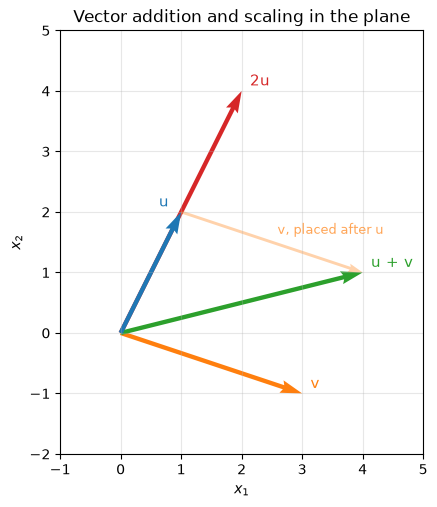

In [2]:
u = np.array([1., 2.])
v = np.array([3., -1.])
print("u + v  =", u + v)
print("2u     =", 2 * u)
print("2u - v =", 2 * u - v)

# the same arithmetic on a data record: one patient visit = (age, systolic BP, cholesterol, BMI)
p_2024 = np.array([54., 130., 210., 27.5])
p_2025 = np.array([55., 142., 198., 28.1])
print("change 2024 -> 2025:", p_2025 - p_2024, "  (BP up, cholesterol down)")

# draw u, v, u + v and 2u as arrows from the origin; the faint arrow shows v placed tip-to-tail after u
fig, ax = plt.subplots(figsize=(5.5, 5.5))
for vec, col, lab, off in [(2 * u, "C3", "2u", (6, 4)), (v, "C1", "v", (6, 4)), (u + v, "C2", "u + v", (6, 4)),
                           (u, "C0", "u", (-16, 4))]:   # u drawn last, on top of 2u; its label sits to the left of the shaft
    ax.quiver(0, 0, vec[0], vec[1], angles="xy", scale_units="xy", scale=1, color=col, width=0.012)
    ax.annotate(lab, vec, textcoords="offset points", xytext=off, color=col, fontsize=11)
ax.quiver(u[0], u[1], v[0], v[1], angles="xy", scale_units="xy", scale=1, color="C1", alpha=0.35, width=0.008)
ax.annotate("v, placed after u", u + v / 2, textcoords="offset points", xytext=(4, 6), color="C1", alpha=0.7, fontsize=9)
ax.set_xlim(-1, 5); ax.set_ylim(-2, 5); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("Vector addition and scaling in the plane")
plt.show()

**Notice that** $\mathbf{u} + \mathbf{v}$ is where you land if you walk along $\mathbf{u}$ and then along $\mathbf{v}$ (the faint arrow): tip-to-tail addition and component-wise addition are the same thing. Scaling by 2 keeps the direction and doubles the length.

**Linear independence.** Vectors are independent when no non-trivial combination gives $\mathbf{0}$ — equivalently, when the matrix with those vectors as columns has rank equal to the number of vectors. Writing a third vector $\mathbf{w}$ in terms of $\mathbf{u}$ and $\mathbf{v}$ means solving two equations in two unknowns. The guide did this by hand for $\mathbf{w} = (5, 0)$ and found $5/7$ and $10/7$.

In [3]:
M = np.column_stack([u, v])                       # 2x2 matrix with u and v as columns
rank = np.linalg.matrix_rank(M)
print("rank of [u v] =", rank, "->", "independent" if rank == 2 else "dependent")

w = np.array([5., 0.])
coeffs = np.linalg.solve(M, w)                    # a*u + b*v = w
print("w = %.4f * u + %.4f * v    (by hand: 5/7 = %.4f, 10/7 = %.4f)" % (coeffs[0], coeffs[1], 5/7, 10/7))
print("check a*u + b*v =", coeffs[0] * u + coeffs[1] * v)

# any three vectors in R^2 are dependent: the rank cannot exceed 2
print("rank of [u v w] =", np.linalg.matrix_rank(np.column_stack([u, v, w])))

rank of [u v] = 2 -> independent
w = 0.7143 * u + 1.4286 * v    (by hand: 5/7 = 0.7143, 10/7 = 1.4286)
check a*u + b*v = [5. 0.]
rank of [u v w] = 2


> **Try it yourself:** replace `v` by `np.array([2., 4.])` (a multiple of `u`) and re-run the two cells above. The rank drops to 1 and `np.linalg.solve` raises `LinAlgError: Singular matrix` — the two arrows lie on one line, so they cannot reach $(5, 0)$.

## 2. Norms and distance

A norm is a ruler. The three you will use constantly:

$$\|\mathbf{x}\|_2 = \sqrt{\sum_i x_i^2}, \qquad \|\mathbf{x}\|_1 = \sum_i |x_i|, \qquad \|\mathbf{x}\|_\infty = \max_i |x_i|,$$

and in general $\|\mathbf{x}\|_p = \big(\sum_i |x_i|^p\big)^{1/p}$. A **unit vector** has norm 1; **normalising** $\mathbf{x}$ means dividing by its norm. The **distance** between two points is the norm of their difference. For $\mathbf{x} = (3, -4, 12)$ the guide found $\|\mathbf{x}\|_2 = 13$, $\|\mathbf{x}\|_1 = 19$ and $\|\mathbf{x}\|_\infty = 12$ — let us compute the $L_2$ norm three ways and confirm the ordering $\|\mathbf{x}\|_\infty \le \|\mathbf{x}\|_2 \le \|\mathbf{x}\|_1 \le \sqrt{n}\,\|\mathbf{x}\|_2$.

In [4]:
x = np.array([3., -4., 12.])

l2_by_hand = np.sqrt(np.sum(x ** 2))     # the definition
l2_dot     = np.sqrt(x @ x)              # via the dot product: ||x||^2 = x . x
l2_numpy   = np.linalg.norm(x)           # the library call
print("L2 three ways      :", l2_by_hand, l2_dot, l2_numpy)

l1, l1_np     = np.sum(np.abs(x)), np.linalg.norm(x, 1)
linf, linf_np = np.max(np.abs(x)), np.linalg.norm(x, np.inf)
print("L1   (ours, numpy) :", l1, l1_np)
print("Linf (ours, numpy) :", linf, linf_np)
print("Linf <= L2 <= L1 <= sqrt(n) L2 :", linf <= l2_dot <= l1 <= np.sqrt(len(x)) * l2_dot,
      "  (sqrt(3) * 13 = %.2f)" % (np.sqrt(3) * 13))

x_hat = x / l2_dot
print("unit vector x_hat  :", x_hat, "  norm:", np.linalg.norm(x_hat))

a, b = np.array([1., 2., 3.]), np.array([4., 6., 3.])
print("distance a <-> b   : L2 = %.3f   L1 = %.3f   Linf = %.3f"
      % (np.linalg.norm(a - b), np.linalg.norm(a - b, 1), np.linalg.norm(a - b, np.inf)))

L2 three ways      : 13.0 13.0 13.0
L1   (ours, numpy) : 19.0 19.0
Linf (ours, numpy) : 12.0 12.0
Linf <= L2 <= L1 <= sqrt(n) L2 : True   (sqrt(3) * 13 = 22.52)
unit vector x_hat  : [ 0.2308 -0.3077  0.9231]   norm: 1.0
distance a <-> b   : L2 = 5.000   L1 = 7.000   Linf = 4.000


The *unit ball* $\{\mathbf{x} : \|\mathbf{x}\|_p \le 1\}$ reveals each norm's personality. We trace its boundary by taking points on the ordinary circle and rescaling each one to have $L_p$ norm exactly 1.

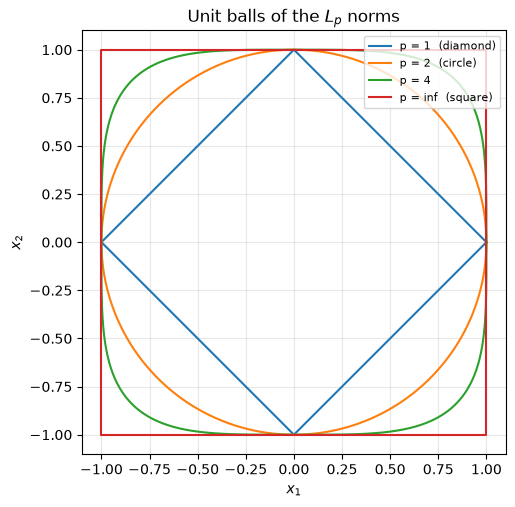

In [5]:
def lp_unit_circle(p, n=721):
    # points on the L2 circle, each rescaled so that its Lp norm equals 1
    t = np.linspace(0, 2 * np.pi, n)
    pts = np.column_stack([np.cos(t), np.sin(t)])
    norms_p = (np.abs(pts) ** p).sum(axis=1) ** (1 / p)
    return pts / norms_p[:, None]

fig, ax = plt.subplots(figsize=(5.5, 5.5))
for p, lab in [(1, "p = 1  (diamond)"), (2, "p = 2  (circle)"), (4, "p = 4")]:
    c = lp_unit_circle(p)
    ax.plot(c[:, 0], c[:, 1], label=lab)
square = np.array([[1, 1], [-1, 1], [-1, -1], [1, -1], [1, 1]], dtype=float)
ax.plot(square[:, 0], square[:, 1], label="p = inf  (square)")
ax.set_aspect("equal"); ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("Unit balls of the $L_p$ norms")
plt.show()

**Notice that** the $L_1$ ball has corners on the coordinate axes — points where one coordinate is exactly zero. When a smooth loss is minimised subject to an $L_1$ constraint, the solution tends to land on such a corner, which is the geometric reason the lasso produces exact zeros (Module 13). The round $L_2$ ball has no corners, so ridge regression only shrinks coefficients. The $L_\infty$ ball is a square: it only cares about the single largest coordinate.

> **Try it yourself:** call `lp_unit_circle(0.5)` and plot it. For $p < 1$ the "ball" is not convex (it caves in towards the origin), which is why $\|\cdot\|_p$ is not a norm for $p < 1$ — the triangle inequality fails.

## 3. The inner (dot) product

$$\mathbf{u}\cdot\mathbf{v} = \sum_i u_i v_i = \|\mathbf{u}\|\,\|\mathbf{v}\|\cos\theta.$$

The algebraic side is a *weighted sum*; the geometric side measures *alignment*. The guide proved the two agree via the law of cosines, $\|\mathbf{u} - \mathbf{v}\|^2 = \|\mathbf{u}\|^2 + \|\mathbf{v}\|^2 - 2\,\mathbf{u}\cdot\mathbf{v}$. We check that identity on a thousand random pairs, together with the two inequalities that follow from it: **Cauchy–Schwarz** $|\mathbf{u}\cdot\mathbf{v}| \le \|\mathbf{u}\|\|\mathbf{v}\|$ and the **triangle inequality** $\|\mathbf{u} + \mathbf{v}\| \le \|\mathbf{u}\| + \|\mathbf{v}\|$.

In [6]:
u, v = np.array([3., 4.]), np.array([4., 3.])
dot = u @ v
cos_theta = dot / (np.linalg.norm(u) * np.linalg.norm(v))
print("u . v = %.1f   cos(theta) = %.3f   theta = %.2f degrees" % (dot, cos_theta, np.degrees(np.arccos(cos_theta))))

# law-of-cosines identity on 1000 random pairs of 5-D vectors (one pair per column)
U = rng.normal(size=(5, 1000)); V = rng.normal(size=(5, 1000))
lhs = np.sum((U - V) ** 2, axis=0)
rhs = np.sum(U ** 2, axis=0) + np.sum(V ** 2, axis=0) - 2 * np.sum(U * V, axis=0)
print("law of cosines: max |lhs - rhs| over 1000 pairs = %.2e" % np.max(np.abs(lhs - rhs)))

dots = np.sum(U * V, axis=0)
nu, nv = np.linalg.norm(U, axis=0), np.linalg.norm(V, axis=0)
print("Cauchy-Schwarz holds for every pair :", bool(np.all(np.abs(dots) <= nu * nv + 1e-12)))
print("triangle inequality holds for every pair:", bool(np.all(np.linalg.norm(U + V, axis=0) <= nu + nv + 1e-12)))
print("largest |u.v| / (||u|| ||v||) observed: %.3f   (equality would need parallel vectors)" % np.max(np.abs(dots) / (nu * nv)))

# orthogonality: rotating (a, b) by 90 degrees gives (-b, a), and the dot product vanishes
perp = np.array([-u[1], u[0]])
print("u =", u, " perp =", perp, " u . perp =", u @ perp)

u . v = 24.0   cos(theta) = 0.960   theta = 16.26 degrees
law of cosines: max |lhs - rhs| over 1000 pairs = 1.07e-14
Cauchy-Schwarz holds for every pair : True
triangle inequality holds for every pair: True
largest |u.v| / (||u|| ||v||) observed: 0.977   (equality would need parallel vectors)
u = [3. 4.]  perp = [-4.  3.]  u . perp = 0.0


**Notice that** the identity holds to floating-point precision ($\sim 10^{-14}$) for every pair, and that the Cauchy–Schwarz ratio never reaches 1 for random vectors — it only equals 1 when one vector is a multiple of the other.

To *see* the two readings of the dot product agree, fix both lengths at 5 and let the angle $\theta$ between $\mathbf{u} = (3, 4)$ and a second vector grow from $0^\circ$ (parallel) to $180^\circ$ (anti-parallel). The weighted sum of components, computed from the coordinates alone, must then follow $\|\mathbf{u}\|\|\mathbf{v}\|\cos\theta = 25\cos\theta$. The worked example's $\mathbf{v} = (4, 3)$, the perpendicular $(-4, 3)$ and $-\mathbf{u}$ are three points on that curve.

largest |u . v - 25 cos(theta)| along the sweep: 7.1e-15


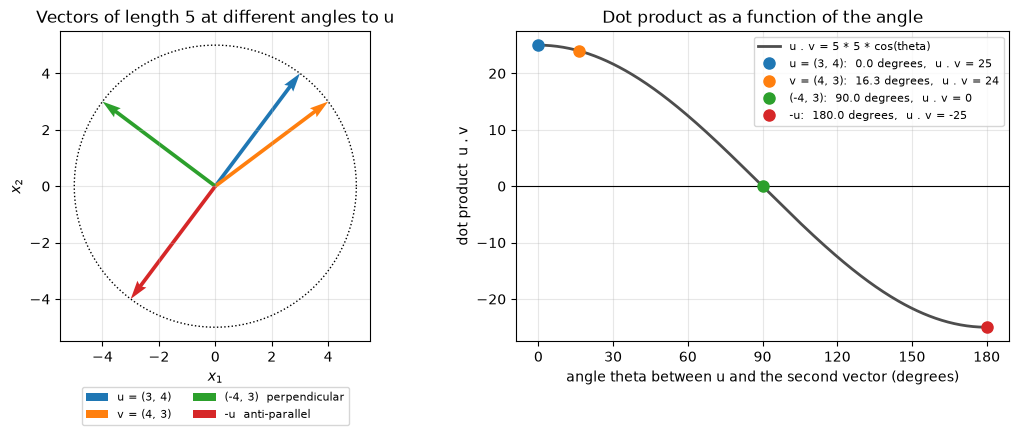

In [7]:
u, v = np.array([3., 4.]), np.array([4., 3.])                 # the worked example again
perp = np.array([-4., 3.])
theta_deg = np.linspace(0, 180, 361)                          # angle between u and the swept vector
phi = np.arctan2(u[1], u[0])                                  # direction of u in the plane
swept = 5 * np.column_stack([np.cos(phi + np.radians(theta_deg)), np.sin(phi + np.radians(theta_deg))])   # length-5 vectors
dot_sweep = swept @ u                                         # one weighted sum per angle, all at once
print("largest |u . v - 25 cos(theta)| along the sweep: %.1e" % np.max(np.abs(dot_sweep - 25 * np.cos(np.radians(theta_deg)))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
ring = np.linspace(0, 2 * np.pi, 200)
ax1.plot(5 * np.cos(ring), 5 * np.sin(ring), "k:", lw=1)                             # every vector of length 5 ends on this circle
ax2.plot(theta_deg, dot_sweep, color="0.3", lw=2, label="u . v = 5 * 5 * cos(theta)")
ax2.axhline(0, color="k", lw=0.8)
marked = [(u, "C0", "u = (3, 4)", 0.0), (v, "C1", "v = (4, 3)", np.degrees(np.arccos(u @ v / 25))),
          (perp, "C2", "(-4, 3)  perpendicular", 90.0), (-u, "C3", "-u  anti-parallel", 180.0)]
for vec, col, lab, ang in marked:
    ax1.quiver(0, 0, vec[0], vec[1], angles="xy", scale_units="xy", scale=1, color=col, width=0.012, label=lab)
    ax2.plot(ang, u @ vec, "o", color=col, ms=8, label="%s:  %.1f degrees,  u . v = %.0f" % (lab.split("  ")[0], ang, u @ vec))
ax1.set_xlim(-5.5, 5.5); ax1.set_ylim(-5.5, 5.5); ax1.set_aspect("equal"); ax1.grid(alpha=0.3)
ax1.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=2)      # below the axes: nothing is hidden
ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_title("Vectors of length 5 at different angles to u")
ax2.set_xticks(range(0, 181, 30)); ax2.grid(alpha=0.3); ax2.legend(fontsize=8, loc="upper right")
ax2.set_xlabel("angle theta between u and the second vector (degrees)"); ax2.set_ylabel("dot product  u . v")
ax2.set_title("Dot product as a function of the angle")
plt.tight_layout(); plt.show()

**Notice that** for two vectors of length 5 the dot product is exactly the curve $25\cos\theta$: it is 25 for $\mathbf{u}$ itself, 24 at the worked example's $16.3^\circ$, crosses zero at $90^\circ$ — the perpendicular $(-4, 3)$ — and bottoms out at $-25$ for $-\mathbf{u}$. The curve was computed from coordinates alone (a weighted sum) and follows the alignment formula to rounding error: the two readings are one quantity.

The *weighted-sum* reading is what a linear model computes: features $\mathbf{x}$, weights $\mathbf{w}$, prediction $\mathbf{w}\cdot\mathbf{x} + b$. The *alignment* reading says the same number is large when the feature vector points along $\mathbf{w}$. And a whole dataset is scored with one matrix–vector product `X @ w`: one dot product per row.

In [8]:
x = np.array([54., 130., 210., 27.5])        # one patient: age, systolic BP, cholesterol, BMI
w = np.array([0.04, 0.02, 0.01, 0.05])       # illustrative risk weights per unit of each feature
b = -8.0
score = w @ x + b
theta = np.arccos((w @ x) / (np.linalg.norm(w) * np.linalg.norm(x)))
print("risk score  w.x + b             = %.3f" % score)
print("same number ||w|| ||x|| cos(theta) + b = %.3f   (theta = %.1f degrees)"
      % (np.linalg.norm(w) * np.linalg.norm(x) * np.cos(theta) + b, np.degrees(theta)))

X = np.array([[54., 130., 210., 27.5],
              [40., 118., 180., 22.0],
              [67., 155., 240., 31.2]])
print("scores for three patients, X @ w + b =", X @ w + b)

risk score  w.x + b             = 0.235
same number ||w|| ||x|| cos(theta) + b = 0.235   (theta = 61.5 degrees)
scores for three patients, X @ w + b = [ 0.235 -1.14   1.74 ]


## 4. Cosine similarity and a toy semantic search

$$\cos(\mathbf{u}, \mathbf{v}) = \frac{\mathbf{u}\cdot\mathbf{v}}{\|\mathbf{u}\|\,\|\mathbf{v}\|} \in [-1, 1]$$

is the dot product of the *normalised* vectors, so it ignores length and compares direction only. Here are eight tiny "documents" as bag-of-words count vectors over a ten-word vocabulary. We search them with the query *"model data loss"* twice — once ranking by cosine similarity and once by Euclidean distance — and watch the two rankings disagree exactly where document length differs.

All eight cosine scores come out of **one matrix–vector product**: normalise the rows of the document matrix $D$, normalise the query, and compute $\hat{D}\hat{\mathbf{q}}$. That is what a vector database does, at scale.

In [9]:
vocab = ["model", "data", "train", "loss", "goal", "match", "team", "coach", "price", "market"]
docs = {
    "ML note (short)":          [2, 1, 1, 0, 0, 0, 0, 0, 0, 0],
    "ML article (long)":        [8, 4, 4, 2, 0, 0, 0, 0, 0, 0],
    "Football report":          [0, 0, 0, 0, 3, 2, 2, 1, 0, 0],
    "Football feature (long)":  [0, 0, 1, 0, 6, 5, 6, 2, 0, 0],
    "Market update":            [0, 1, 0, 0, 0, 0, 0, 0, 3, 3],
    "ML for trading":           [2, 2, 0, 0, 0, 0, 0, 0, 2, 2],
    "Sports analytics":         [1, 2, 0, 0, 0, 1, 2, 0, 0, 0],
    "Coach interview":          [0, 0, 2, 0, 0, 0, 2, 3, 0, 0],
}
names = list(docs)
D = np.array([docs[n] for n in names], dtype=float)                 # 8 x 10 document-term matrix
query = np.array([1, 1, 0, 1, 0, 0, 0, 0, 0, 0], dtype=float)       # "model data loss"

def normalize_rows(M):
    n = np.linalg.norm(M, axis=1, keepdims=True)
    return M / np.where(n == 0, 1.0, n)                             # leave all-zero rows alone

cos_scores = normalize_rows(D) @ (query / np.linalg.norm(query))    # all eight cosines at once
euc_dists  = np.linalg.norm(D - query, axis=1)

order_cos = np.argsort(-cos_scores, kind="stable")                  # best first; exact ties (cosine 0, equal distances) keep list order
order_euc = np.argsort(euc_dists, kind="stable")
print(f"{'rank':<6}{'by cosine similarity':<26}{'cos':>6}      {'by Euclidean distance':<26}{'dist':>6}")
print("-" * 80)
for r in range(len(names)):
    i, j = order_cos[r], order_euc[r]
    print(f"{r + 1:<6}{names[i]:<26}{cos_scores[i]:6.3f}      {names[j]:<26}{euc_dists[j]:6.3f}")
print("\nnorm of each document vector:", np.linalg.norm(D, axis=1))

rank  by cosine similarity         cos      by Euclidean distance       dist
--------------------------------------------------------------------------------
1     ML article (long)          0.808      ML note (short)            1.732
2     ML note (short)            0.707      Sports analytics           2.646
3     ML for trading             0.577      ML for trading             3.317
4     Sports analytics           0.548      Market update              4.472
5     Market update              0.132      Coach interview            4.472
6     Football report            0.000      Football report            4.583
7     Football feature (long)    0.000      ML article (long)          8.660
8     Coach interview            0.000      Football feature (long)   10.247

norm of each document vector: [ 2.4495 10.      4.2426 10.0995  4.3589  4.      3.1623  4.1231]


**Notice that** cosine ranks the long ML article at the top — it is the most "about" the query — while Euclidean distance pushes it far down the list, below *Sports analytics* and *ML for trading*, purely because its vector is long ($\|\mathbf{d}\| \approx 10$ versus $\approx 2.4$ for the short note). Euclidean distance mixes "different topic" with "different length"; cosine measures topic only.

The slope chart below follows every document from its cosine rank to its Euclidean rank and colours it by its length.

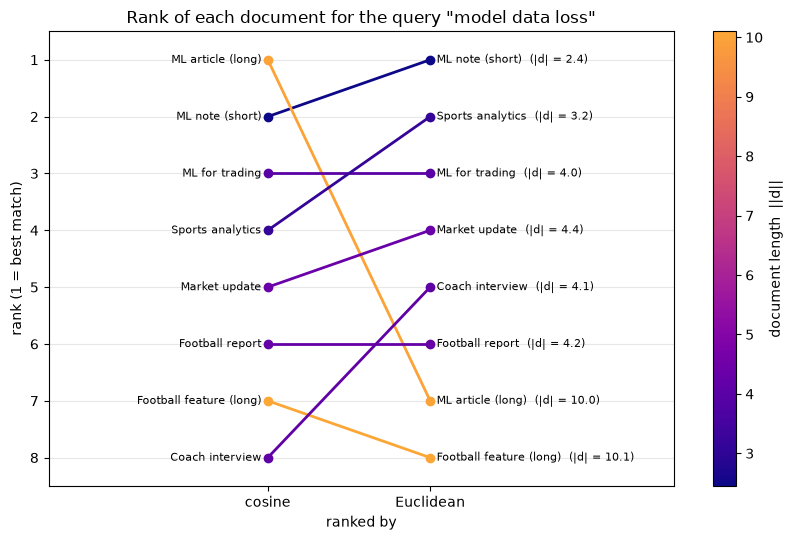

In [10]:
from matplotlib.colors import ListedColormap

rank_cos = np.empty(len(names), dtype=int); rank_cos[order_cos] = np.arange(1, len(names) + 1)     # rank 1 = best match
rank_euc = np.empty(len(names), dtype=int); rank_euc[order_euc] = np.arange(1, len(names) + 1)
doc_len = np.linalg.norm(D, axis=1)
cmap = ListedColormap(plt.get_cmap("plasma")(np.linspace(0, 0.8, 256)))                            # plasma without its pale yellow end
len_norm = plt.Normalize(doc_len.min(), doc_len.max())

fig, ax = plt.subplots(figsize=(8.5, 5.5))
for i, name in enumerate(names):
    ax.plot([0, 1], [rank_cos[i], rank_euc[i]], "o-", lw=2, ms=6, color=cmap(len_norm(doc_len[i])))
    ax.text(-0.04, rank_cos[i], name, ha="right", va="center", fontsize=8)
    ax.text(1.04, rank_euc[i], "%s  (|d| = %.1f)" % (name, doc_len[i]), ha="left", va="center", fontsize=8)
ax.set_xlim(-1.35, 2.5); ax.set_ylim(8.5, 0.5); ax.set_yticks(range(1, 9))
ax.set_xticks([0, 1]); ax.set_xticklabels(["cosine", "Euclidean"]); ax.grid(alpha=0.3, axis="y")
plt.colorbar(plt.cm.ScalarMappable(norm=len_norm, cmap=cmap), ax=ax, label="document length  ||d||")
ax.set_xlabel("ranked by"); ax.set_ylabel("rank (1 = best match)")
ax.set_title('Rank of each document for the query "model data loss"')
plt.tight_layout(); plt.show()

**Notice that** the line that plunges is the long ML article (orange, $\|\mathbf{d}\| = 10$): it falls from first place to seventh although it is the most relevant document. The other long document, the football feature (also orange, $\|\mathbf{d}\| \approx 10.1$), shares no word with the query and sits at seventh and eighth place under the two rankings. The two shortest documents ($\|\mathbf{d}\| \approx 2.4$ and $3.2$) take the top two Euclidean places. Euclidean distance ranks partly by length; cosine ranks by direction alone. (The three documents with cosine 0 share no word with the query, so their order at ranks 6–8 is arbitrary.)

The full pairwise picture is the matrix $\hat{D}\hat{D}^\top$ of all document–document cosines.

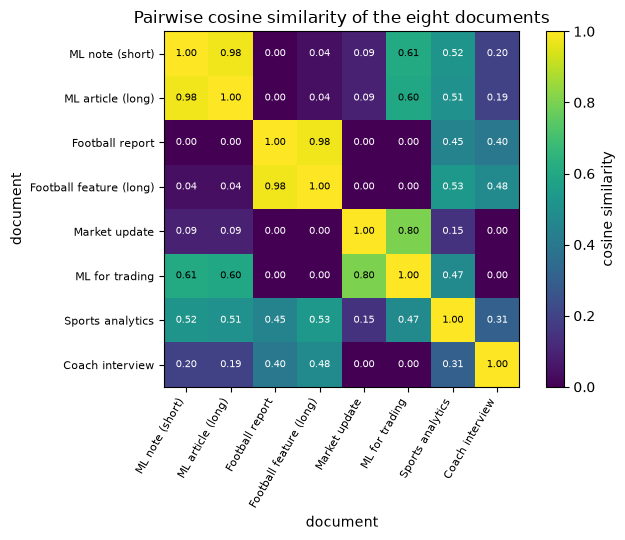

ML note vs ML article: cos = 0.980  (same topic, about 4x the length; below 1 only because the article also mentions 'loss')
ML note vs Football report: cos = 0.000  (no shared words)


In [11]:
Dn = normalize_rows(D)
S = Dn @ Dn.T                                      # 8 x 8 matrix of pairwise cosine similarities

fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(S, cmap="viridis", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_yticks(range(len(names)))
ax.set_xticklabels(names, rotation=60, ha="right", fontsize=8); ax.set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        ax.text(j, i, f"{S[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w" if S[i, j] < 0.6 else "k")
plt.colorbar(im, ax=ax, label="cosine similarity")
ax.set_title("Pairwise cosine similarity of the eight documents"); ax.set_xlabel("document"); ax.set_ylabel("document")
plt.tight_layout(); plt.show()

print("ML note vs ML article: cos = %.3f  (same topic, about 4x the length; below 1 only because the article also mentions 'loss')" % S[0, 1])
print("ML note vs Football report: cos = %.3f  (no shared words)" % S[0, 2])

> **Try it yourself:** change the query to *"goal team price"* (`[0,0,0,0,1,0,1,0,1,0]`) and re-run the search. Then multiply the query by 10 — which of the two rankings changes, and why?

## 5. Projections

The projection of $\mathbf{a}$ onto the line through $\mathbf{b}$, and the residual left over:

$$\mathbf{p} = \frac{\mathbf{a}\cdot\mathbf{b}}{\mathbf{b}\cdot\mathbf{b}}\,\mathbf{b}, \qquad \mathbf{r} = \mathbf{a} - \mathbf{p}, \qquad \mathbf{r}\cdot\mathbf{b} = 0.$$

$\mathbf{p}$ is the *best approximation* of $\mathbf{a}$ among all multiples $t\mathbf{b}$: the squared error $\|\mathbf{a} - t\mathbf{b}\|^2$ is a parabola in $t$ whose minimum sits at $t^\star = \mathbf{a}\cdot\mathbf{b}/\mathbf{b}\cdot\mathbf{b}$. The guide's example is $\mathbf{a} = (2, 3)$, $\mathbf{b} = (4, 2)$, giving $t^\star = 0.7$, $\mathbf{p} = (2.8, 1.4)$ and $\mathbf{r} = (-0.8, 1.6)$.

t* = 0.700   p = [2.8 1.4]   r = [-0.8  1.6]   r . b = 8.88e-16
Pythagoras: ||p||^2 + ||r||^2 = 13.000   ||a||^2 = 13.000
fraction of ||a||^2 explained by direction b: 0.754  (= cos^2 theta)


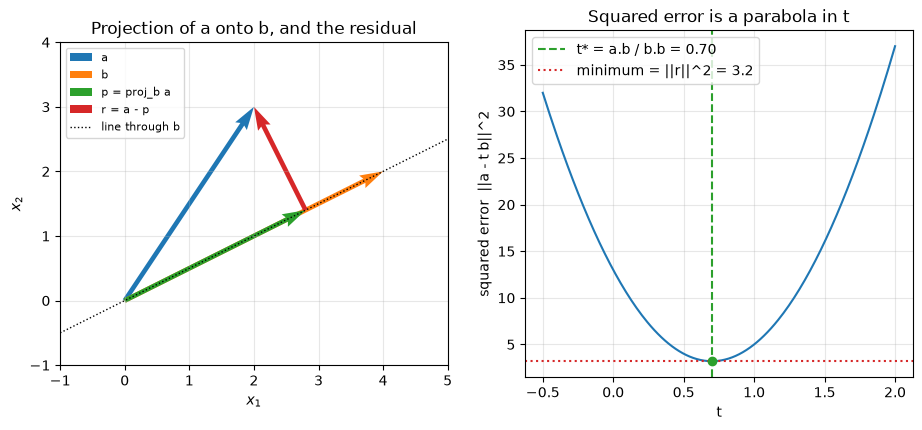

In [12]:
a, b = np.array([2., 3.]), np.array([4., 2.])
t_star = (a @ b) / (b @ b)
p = t_star * b
r = a - p
print("t* = %.3f   p = %s   r = %s   r . b = %.2e" % (t_star, p, r, r @ b))
print("Pythagoras: ||p||^2 + ||r||^2 = %.3f   ||a||^2 = %.3f" % (p @ p + r @ r, a @ a))
print("fraction of ||a||^2 explained by direction b: %.3f  (= cos^2 theta)" % ((p @ p) / (a @ a)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
for vec, col, lab in [(a, "C0", "a"), (b, "C1", "b"), (p, "C2", "p = proj_b a")]:
    ax1.quiver(0, 0, vec[0], vec[1], angles="xy", scale_units="xy", scale=1, color=col, width=0.012, label=lab)
ax1.quiver(p[0], p[1], r[0], r[1], angles="xy", scale_units="xy", scale=1, color="C3", width=0.012, label="r = a - p")
ax1.plot([-1, 5], [-0.5, 2.5], "k:", lw=1, label="line through b")
ax1.set_xlim(-1, 5); ax1.set_ylim(-1, 4); ax1.set_aspect("equal"); ax1.grid(alpha=0.3); ax1.legend(fontsize=8, loc="upper left")
ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_title("Projection of a onto b, and the residual")

ts = np.linspace(-0.5, 2.0, 200)
errs = [np.sum((a - t * b) ** 2) for t in ts]
ax2.plot(ts, errs)
ax2.axvline(t_star, color="C2", ls="--", label="t* = a.b / b.b = %.2f" % t_star)
ax2.set_xlabel("t"); ax2.set_ylabel("squared error  ||a - t b||^2"); ax2.set_title("Squared error is a parabola in t")
ax2.axhline(r @ r, color="C3", ls=":", label="minimum = ||r||^2 = %.1f" % (r @ r))
ax2.plot(t_star, r @ r, "o", color="C2")
ax2.legend(); ax2.grid(alpha=0.3)
plt.show()

**Notice that** the residual arrow meets the dotted line at a right angle — $\mathbf{r}\cdot\mathbf{b}$ is zero to machine precision — and that the parabola's minimum is exactly at $t^\star$, where the squared error equals $\|\mathbf{r}\|^2 = 3.2$ (the dotted red level): no multiple of $\mathbf{b}$ gets closer to $\mathbf{a}$ than the projection does. Replace the single direction $\mathbf{b}$ by several feature columns and the same picture becomes *least squares*: the fitted values are the projection of the target onto the span of the columns, and the residual vector is orthogonal to every column (Module 02).

## 6. Orthonormal bases and Gram–Schmidt

Vectors $\mathbf{q}_1, \dots, \mathbf{q}_n$ are **orthonormal** when $\mathbf{q}_i\cdot\mathbf{q}_j = 1$ if $i = j$ and $0$ otherwise; as columns of $Q$, this reads $Q^\top Q = I$. Coordinates are then just dot products, and lengths are preserved (Parseval):

$$\mathbf{x} = \sum_i c_i\,\mathbf{q}_i, \qquad c_i = \mathbf{x}\cdot\mathbf{q}_i, \qquad \|\mathbf{x}\|^2 = \sum_i c_i^2 .$$

**Gram–Schmidt** turns any independent set into an orthonormal one: take each new vector, subtract its projections onto the directions already built, normalise. Below is the *modified* variant (each subtraction uses the already-reduced vector, which is numerically a little kinder); `np.linalg.qr` does the same job with Householder reflections, so its columns may differ from ours by a sign.

In [13]:
def gram_schmidt(A):
    # Columns of A (linearly independent) -> Q with orthonormal columns and the same span.
    A = np.asarray(A, dtype=float)
    Q = np.zeros_like(A)
    for j in range(A.shape[1]):
        v = A[:, j].copy()
        for i in range(j):
            v -= (v @ Q[:, i]) * Q[:, i]            # remove the component along q_i
        Q[:, j] = v / np.linalg.norm(v)
    return Q

A = np.column_stack([[1., 1., 0.], [1., 0., 1.], [0., 1., 1.]])      # a1, a2, a3 from the guide
Q = gram_schmidt(A)
print("Q =\n", Q)
print("by hand: q1 = (1,1,0)/sqrt2, q2 = (1,-1,2)/sqrt6, q3 = (-1,1,1)/sqrt3 ->\n",
      np.column_stack([[1, 1, 0] / np.sqrt(2), [1, -1, 2] / np.sqrt(6), [-1, 1, 1] / np.sqrt(3)]))
print("Q^T Q =\n", Q.T @ Q)

Q_qr, R = np.linalg.qr(A)
print("agrees with np.linalg.qr up to column signs:", np.allclose(np.abs(Q), np.abs(Q_qr)))

x = np.array([3., 1., 2.])
c = Q.T @ x                                        # coordinates = dot products with the basis vectors
print("coordinates of x = (3, 1, 2) in the new basis:", c)
print("reconstruction Q c =", Q @ c, "   Parseval: sum c_i^2 = %.3f, ||x||^2 = %.3f" % (c @ c, x @ x))

Q =
 [[ 0.7071  0.4082 -0.5774]
 [ 0.7071 -0.4082  0.5774]
 [ 0.      0.8165  0.5774]]
by hand: q1 = (1,1,0)/sqrt2, q2 = (1,-1,2)/sqrt6, q3 = (-1,1,1)/sqrt3 ->
 [[ 0.7071  0.4082 -0.5774]
 [ 0.7071 -0.4082  0.5774]
 [ 0.      0.8165  0.5774]]
Q^T Q =
 [[ 1.  0.  0.]
 [ 0.  1. -0.]
 [ 0. -0.  1.]]
agrees with np.linalg.qr up to column signs: True
coordinates of x = (3, 1, 2) in the new basis: [ 2.8284  2.4495 -0.    ]
reconstruction Q c = [3. 1. 2.]    Parseval: sum c_i^2 = 14.000, ||x||^2 = 14.000


**Notice that** the third coordinate of $\mathbf{x}$ is zero: $\mathbf{x}$ lies in the plane spanned by $\mathbf{a}_1$ and $\mathbf{a}_2$ (indeed $\mathbf{x} = \mathbf{a}_1 + 2\mathbf{a}_2$), and the orthonormal basis makes that visible at a glance.

The algorithm is easiest to *see* in the plane. Take $\mathbf{a}_1 = (4, 1)$ and $\mathbf{a}_2 = (2, 3)$. The first step keeps the direction of $\mathbf{a}_1$ and shrinks it to length 1, giving $\mathbf{q}_1$. The second subtracts from $\mathbf{a}_2$ its projection onto $\mathbf{q}_1$ — Section 5 again — and rescales what is left to length 1, giving $\mathbf{q}_2$. Then we read off the coordinates of $\mathbf{x} = (3, 2)$ in the new basis.

q1 = [0.9701 0.2425]   q2 = [-0.2425  0.9701]   q1 . q2 = 1.4e-16
same columns as gram_schmidt() above: True
coordinates of x = (3, 2): (3.395, 1.213)   sum of squares = 13.000,  ||x||^2 = 13.000


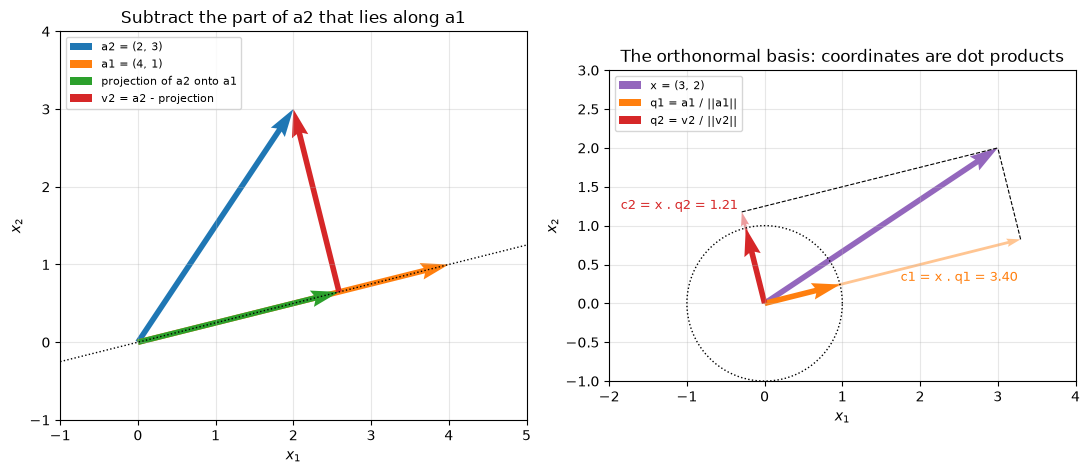

In [14]:
a1, a2 = np.array([4., 1.]), np.array([2., 3.])
q1 = a1 / np.linalg.norm(a1)                              # step 1: keep the direction of a1, make it a unit vector
proj = (a2 @ q1) * q1                                     # step 2: the part of a2 along q1 (Section 5) ...
v2 = a2 - proj                                            # ... removed, leaving the residual ...
q2 = v2 / np.linalg.norm(v2)                              # ... which is then normalised
print("q1 =", q1, "  q2 =", q2, "  q1 . q2 = %.1e" % (q1 @ q2))
print("same columns as gram_schmidt() above:", np.allclose(gram_schmidt(np.column_stack([a1, a2])), np.column_stack([q1, q2])))

x2 = np.array([3., 2.])
c2 = np.array([x2 @ q1, x2 @ q2])                         # coordinates of x2 in the new basis: two dot products
print("coordinates of x = (3, 2): (%.3f, %.3f)   sum of squares = %.3f,  ||x||^2 = %.3f" % (c2[0], c2[1], c2 @ c2, x2 @ x2))

def arrow(ax, vec, start=(0, 0), width=0.012, **kw):
    ax.quiver(start[0], start[1], vec[0], vec[1], angles="xy", scale_units="xy", scale=1, width=width, **kw)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.8))
arrow(ax1, a2, color="C0", label="a2 = (2, 3)")
arrow(ax1, a1, color="C1", label="a1 = (4, 1)")
arrow(ax1, proj, color="C2", label="projection of a2 onto a1")
arrow(ax1, v2, start=proj, color="C3", label="v2 = a2 - projection")
ax1.plot([-1, 5], [-0.25, 1.25], "k:", lw=1)              # the line through a1
ax1.set_xlim(-1, 5); ax1.set_ylim(-1, 4); ax1.set_aspect("equal"); ax1.grid(alpha=0.3); ax1.legend(fontsize=8, loc="upper left")
ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$"); ax1.set_title("Subtract the part of a2 that lies along a1")

ring = np.linspace(0, 2 * np.pi, 200)
ax2.plot(np.cos(ring), np.sin(ring), "k:", lw=1)          # the unit circle
arrow(ax2, x2, color="C4", label="x = (3, 2)")
arrow(ax2, q1, color="C1", label="q1 = a1 / ||a1||")
arrow(ax2, q2, color="C3", label="q2 = v2 / ||v2||")
for k, col in [(0, "C1"), (1, "C3")]:                     # thin arrows c1 q1 and c2 q2: the walk that reaches x
    qk = (q1, q2)[k]
    arrow(ax2, c2[k] * qk, color=col, alpha=0.45, width=0.006)
    ax2.plot([c2[k] * qk[0], x2[0]], [c2[k] * qk[1], x2[1]], "k--", lw=0.8)
ax2.text(*(c2[0] * q1 / 2), "  c1 = x . q1 = %.2f" % c2[0], color="C1", va="top", fontsize=9)
ax2.text(*(c2[1] * q2), "c2 = x . q2 = %.2f " % c2[1], color="C3", ha="right", va="bottom", fontsize=9)
ax2.set_xlim(-2, 4); ax2.set_ylim(-1, 3); ax2.set_aspect("equal"); ax2.grid(alpha=0.3); ax2.legend(fontsize=8, loc="upper left")
ax2.set_xlabel("$x_1$"); ax2.set_ylabel("$x_2$"); ax2.set_title("The orthonormal basis: coordinates are dot products")
plt.tight_layout(); plt.show()

**Notice that** $\mathbf{q}_2$ is exactly Section 5's residual, rescaled to length 1: Gram–Schmidt is projection repeated, one earlier direction at a time. Once $\mathbf{q}_1$ and $\mathbf{q}_2$ are orthonormal, the coordinates of $\mathbf{x} = (3, 2)$ are two dot products, $3.40$ and $1.21$, and their squares add up to $13 = \|\mathbf{x}\|^2$ (Parseval) — the same bookkeeping the 3-D example above does with three vectors.

The same idea organises colour: a pixel's $(R, G, B)$ values re-expressed in a brightness/chroma basis put almost all of their energy into the brightness coordinate (the cell below finds about 93% for one pixel, and natural images behave similarly because their colour channels are strongly correlated). Together with the eye's much lower acuity for colour detail, this is why image codecs such as JPEG compress chroma far more aggressively than luma.

In [15]:
pixel = np.array([200., 150., 100.])                       # (R, G, B)
B = np.column_stack([np.ones(3) / np.sqrt(3),              # brightness direction
                     np.array([1., 0., -1.]) / np.sqrt(2),  # red-versus-blue
                     np.array([1., -2., 1.]) / np.sqrt(6)]) # green-versus-magenta
coords = B.T @ pixel
print("B^T B = I :", np.allclose(B.T @ B, np.eye(3)))
print("coordinates (brightness, red-blue, green-magenta):", coords)
print("share of the pixel's energy in the brightness coordinate: %.1f%%" % (100 * coords[0] ** 2 / (pixel @ pixel)))
print("Parseval: %.1f = %.1f" % (coords @ coords, pixel @ pixel))

B^T B = I : True
coordinates (brightness, red-blue, green-magenta): [259.8076  70.7107  -0.    ]
share of the pixel's energy in the brightness coordinate: 93.1%
Parseval: 72500.0 = 72500.0


> **Try it yourself:** feed `gram_schmidt` three *nearly* dependent columns, e.g. `np.column_stack([[1,1,1], [1,1,1+1e-8], [1,1+1e-8,1]])`, and compare `Q.T @ Q` with the result of `np.linalg.qr`. How far from the identity is each? (This is why production code uses QR or SVD rather than textbook Gram–Schmidt.)

## 7. Hyperplanes and half-spaces

The set $\{\mathbf{x} : \mathbf{w}\cdot\mathbf{x} + b = 0\}$ is a hyperplane with **normal vector** $\mathbf{w}$. The **signed distance** of any point to it is

$$\delta(\mathbf{x}) = \frac{\mathbf{w}\cdot\mathbf{x} + b}{\|\mathbf{w}\|},$$

positive on the side $\mathbf{w}$ points to. A linear classifier predicts $\operatorname{sign}(\mathbf{w}\cdot\mathbf{x} + b)$, and the **margin** of a labelled point is $y\,\delta(\mathbf{x})$.

The simplest linear classifier is *nearest centroid*: assign a point to whichever class mean is closer. Working out $\|\mathbf{x} - \boldsymbol{\mu}_1\|^2 < \|\mathbf{x} - \boldsymbol{\mu}_0\|^2$ shows that this is a hyperplane with $\mathbf{w} = \boldsymbol{\mu}_1 - \boldsymbol{\mu}_0$ passing through the midpoint of the two centroids, i.e. $b = -\mathbf{w}\cdot(\boldsymbol{\mu}_0 + \boldsymbol{\mu}_1)/2$.

w = [2.4723 2.1289]   b = -9.622  ||w|| = 3.263
training accuracy: 0.992    misclassified: 1
smallest positive margin: 0.156
rescaling (w, b) by 10 leaves every signed distance unchanged: True


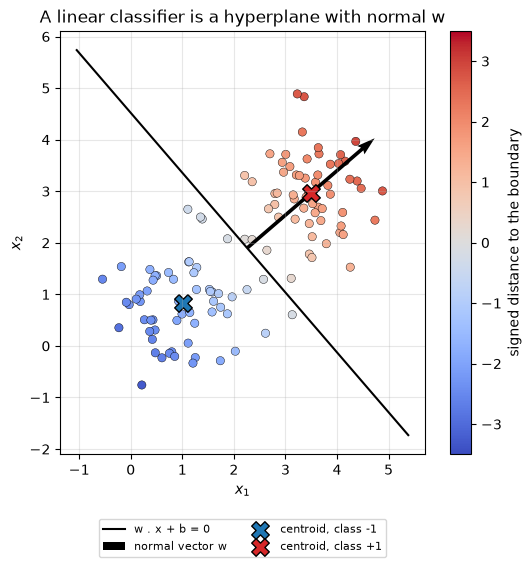

In [16]:
n = 60
X0 = rng.normal(loc=[1.0, 1.0], scale=0.7, size=(n, 2))      # class -1
X1 = rng.normal(loc=[3.5, 3.0], scale=0.7, size=(n, 2))      # class +1
X = np.vstack([X0, X1]); y = np.array([-1] * n + [1] * n)

mu0, mu1 = X0.mean(axis=0), X1.mean(axis=0)
w = mu1 - mu0                                   # normal vector, pointing from class -1 towards class +1
b = -w @ (mu0 + mu1) / 2                        # boundary through the midpoint of the centroids
signed = (X @ w + b) / np.linalg.norm(w)        # signed distances, all points at once
pred = np.where(signed > 0, 1, -1)
margins = y * signed
print("w =", w, "  b = %.3f  ||w|| = %.3f" % (b, np.linalg.norm(w)))
print("training accuracy: %.3f    misclassified: %d" % (np.mean(pred == y), np.sum(margins <= 0)))
print("smallest positive margin: %.3f" % margins[margins > 0].min())
print("rescaling (w, b) by 10 leaves every signed distance unchanged:",
      np.allclose((X @ (10 * w) + 10 * b) / np.linalg.norm(10 * w), signed))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sc = ax.scatter(X[:, 0], X[:, 1], c=signed, cmap="coolwarm", vmin=-3.5, vmax=3.5, edgecolor="k", lw=0.3)
plt.colorbar(sc, ax=ax, label="signed distance to the boundary")
xs = np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 50)
ax.plot(xs, -(w[0] * xs + b) / w[1], "k-", label="w . x + b = 0")
mid = (mu0 + mu1) / 2
ax.quiver(mid[0], mid[1], w[0], w[1], angles="xy", scale_units="xy", scale=1, color="k", width=0.01, label="normal vector w")
ax.scatter(mu0[0], mu0[1], marker="X", s=160, c="C0", edgecolor="k", label="centroid, class -1")
ax.scatter(mu1[0], mu1[1], marker="X", s=160, c="C3", edgecolor="k", label="centroid, class +1")
ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=2)      # below the axes: nothing is hidden
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_title("A linear classifier is a hyperplane with normal w")
plt.show()

**Notice that** $\mathbf{w}$ is *perpendicular* to the decision line, not along it, and that the colour (signed distance) changes only as you move in the direction of $\mathbf{w}$ — moving parallel to the boundary changes nothing. Scaling $(\mathbf{w}, b)$ changes the raw scores but not the boundary or the distances; on separable data, though, the logistic loss keeps falling as $\mathbf{w}$ is scaled up, so logistic regression needs a regulariser to pin down the scale of $\mathbf{w}$.

Recall the **margin** $y\,\delta(\mathbf{x})$ of a labelled point: positive when the point is on the correct side, and larger the farther it is from the boundary. The histogram below folds both classes onto that single axis.

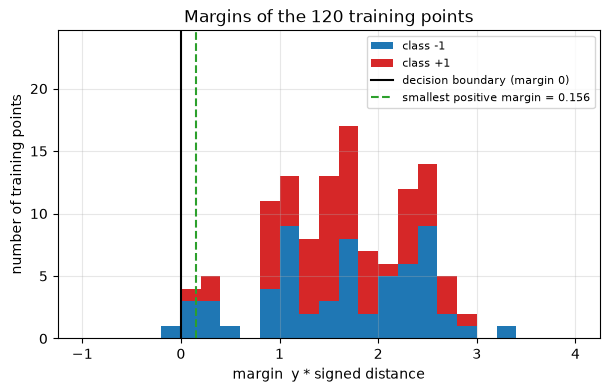

margins below 0: 1   between 0 and 0.5: 9   above 0.5: 110


In [17]:
smallest = margins[margins > 0].min()                      # reuses margins = y * signed from the cell above
fig, ax = plt.subplots(figsize=(7, 4))
bins = np.linspace(-1, 4, 26)
stacks, _, _ = ax.hist([margins[y == -1], margins[y == 1]], bins=bins, stacked=True, color=["C0", "C3"], label=["class -1", "class +1"])
ax.axvline(0, color="k", label="decision boundary (margin 0)")
ax.axvline(smallest, color="C2", ls="--", label="smallest positive margin = %.3f" % smallest)
ax.set_ylim(0, 1.45 * stacks[-1].max())                     # head-room for the legend
ax.set_xlabel("margin  y * signed distance"); ax.set_ylabel("number of training points")
ax.set_title("Margins of the %d training points" % len(y)); ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.3)
plt.show()
print("margins below 0: %d   between 0 and 0.5: %d   above 0.5: %d" % (np.sum(margins < 0), np.sum((margins >= 0) & (margins < 0.5)), np.sum(margins >= 0.5)))

**Notice that** everything to the right of zero is correctly classified, the single point to the left (margin about $-0.08$) is the misclassified one, and the nine points with margins between $0$ and $0.5$ are those a slightly different training set would flip. A support vector machine chooses $\mathbf{w}, b$ to push the left edge of this histogram — the smallest margin — as far to the right as possible.

## 8. High-dimensional geometry

Everything so far holds in any dimension, but the *typical* behaviour of random points changes completely as $d$ grows. For two random vectors with independent standard-normal coordinates,

$$\mathbb{E}[\cos(\mathbf{u}, \mathbf{v})] = 0, \qquad \operatorname{sd}[\cos(\mathbf{u}, \mathbf{v})] = \frac{1}{\sqrt d},$$

so random directions become nearly orthogonal. We draw 300 random vectors for $d = 2, 10, 100, 1000$, compute **all pairwise cosines in one matrix product** $\hat{Z}\hat{Z}^\top$, and compare the spread with $1/\sqrt d$.

     d  std of cosine  1/sqrt(d)  max |cos|
     2         0.7077     0.7071      1.000
    10         0.3150     0.3162      0.955


   100         0.0999     0.1000      0.405
  1000         0.0315     0.0316      0.133


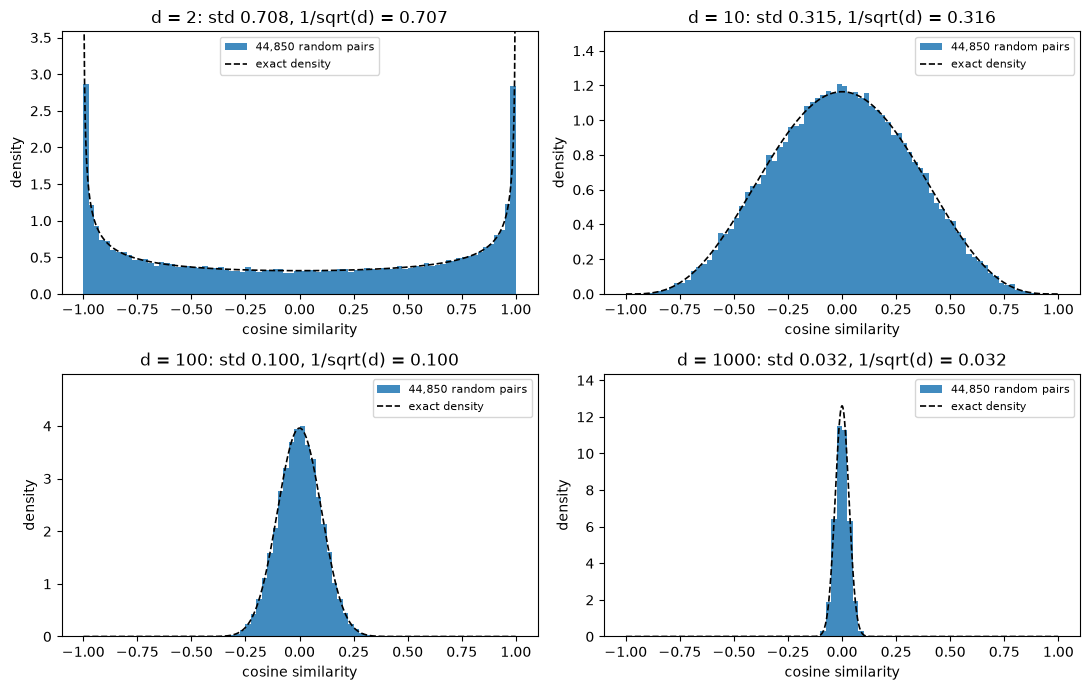

In [18]:
from scipy.special import gammaln

dims, n = [2, 10, 100, 1000], 300
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
print(f"{'d':>6} {'std of cosine':>14} {'1/sqrt(d)':>10} {'max |cos|':>10}")
for ax, d in zip(axes.ravel(), dims):
    Z = rng.normal(size=(n, d))
    Zn = Z / np.linalg.norm(Z, axis=1, keepdims=True)
    C = Zn @ Zn.T                                        # all n x n cosines at once
    cosines = C[np.triu_indices(n, k=1)]                 # each unordered pair exactly once
    print(f"{d:>6} {cosines.std():>14.4f} {1 / np.sqrt(d):>10.4f} {np.abs(cosines).max():>10.3f}")
    heights, _, _ = ax.hist(cosines, bins=80, range=(-1, 1), density=True, color="C0", alpha=0.85,
                            label=f"{n * (n - 1) // 2:,} random pairs")
    t = np.linspace(-0.999, 0.999, 800)                  # exact density of the cosine of two random directions in R^d,
    pdf = np.exp(gammaln(d / 2) - gammaln((d - 1) / 2)) / np.sqrt(np.pi) * (1 - t ** 2) ** ((d - 3) / 2)   # the arcsine law when d = 2
    ax.plot(t, pdf, "k--", lw=1.2, label="exact density")
    ax.set_ylim(0, 1.25 * heights.max())                 # the arcsine density is infinite at +-1: clip it to the axis
    ax.set_title(f"d = {d}: std {cosines.std():.3f}, 1/sqrt(d) = {1 / np.sqrt(d):.3f}")
    ax.set_xlabel("cosine similarity"); ax.set_ylabel("density"); ax.legend(fontsize=8, loc="best")
plt.tight_layout(); plt.show()

**Notice that** the measured standard deviation tracks $1/\sqrt d$ almost perfectly (each title prints both), the histograms follow the exact density drawn as a dashed curve, and at $d = 1000$ no pair out of 44,850 reaches a cosine of even $0.15$. That density is proportional to $(1 - t^2)^{(d-3)/2}$: the arcsine law for $d = 2$ and, as $d$ grows, a bell curve of variance exactly $1/d$. (In $d = 2$ the histogram piles up at $\pm 1$: the cosine of a uniformly random angle has an arcsine-shaped density, so in the plane random directions are *more* likely to be nearly parallel than nearly perpendicular — the opposite of high dimensions.) This is the baseline against which any "similarity" must be judged: a cosine of $0.3$ is nothing in 10 dimensions and nearly a ten-sigma event in 1000.

The second surprise is **distance concentration**. For random points in the unit cube, $\|\mathbf{x} - \mathbf{y}\|^2$ is a sum of $d$ independent terms, so its relative spread shrinks like $1/\sqrt d$ — the nearest and the farthest neighbour end up at almost the same distance.

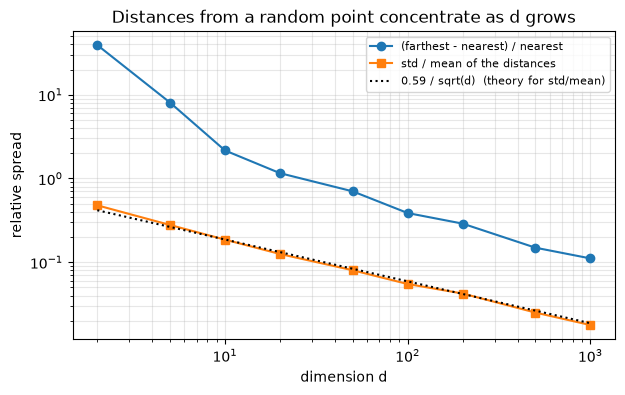

d =     2: farthest neighbour is  3917.7% farther than the nearest;  std/mean = 0.478
d =     5: farthest neighbour is   806.2% farther than the nearest;  std/mean = 0.278
d =    10: farthest neighbour is   215.9% farther than the nearest;  std/mean = 0.186
d =    20: farthest neighbour is   115.6% farther than the nearest;  std/mean = 0.125
d =    50: farthest neighbour is    70.2% farther than the nearest;  std/mean = 0.080
d =   100: farthest neighbour is    38.6% farther than the nearest;  std/mean = 0.055
d =   200: farthest neighbour is    28.9% farther than the nearest;  std/mean = 0.042
d =   500: farthest neighbour is    14.9% farther than the nearest;  std/mean = 0.025
d =  1000: farthest neighbour is    11.1% farther than the nearest;  std/mean = 0.018


In [19]:
dims, n = [2, 5, 10, 20, 50, 100, 200, 500, 1000], 500
contrast, rel_spread = [], []
for d in dims:
    P = rng.random((n, d))                               # uniform in the unit cube
    dist = np.linalg.norm(P[1:] - P[0], axis=1)          # distances from the first point to all others
    contrast.append((dist.max() - dist.min()) / dist.min())
    rel_spread.append(dist.std() / dist.mean())

fig, ax = plt.subplots()
ax.plot(dims, contrast, "o-", label="(farthest - nearest) / nearest")
ax.plot(dims, rel_spread, "s-", label="std / mean of the distances")
ax.plot(dims, 0.59 / np.sqrt(np.array(dims, float)), "k:", label="0.59 / sqrt(d)  (theory for std/mean)")
ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
ax.set_xlabel("dimension d"); ax.set_ylabel("relative spread"); ax.set_title("Distances from a random point concentrate as d grows")
plt.show()
for d, c, s in zip(dims, contrast, rel_spread):
    print(f"d = {d:>5}: farthest neighbour is {100 * c:7.1f}% farther than the nearest;  std/mean = {s:.3f}")

**Notice that** in two dimensions the farthest point is tens of times farther away than the nearest, while at $d = 1000$ the difference is only about ten per cent. A nearest-neighbour method on raw 1000-dimensional noise is essentially picking at random. (The dotted theory line: the relative spread of the *squared* distance is $\approx 1.18/\sqrt d$, and taking the square root halves relative fluctuations, giving $\approx 0.59/\sqrt d$ for the distance itself.)

Third surprise: **volume lives in the corners.** The unit ball has volume $V_d = \pi^{d/2}/\Gamma(d/2 + 1)$, the cube $[-1, 1]^d$ around it has volume $2^d$. We compare the exact ratio with a Monte Carlo estimate.

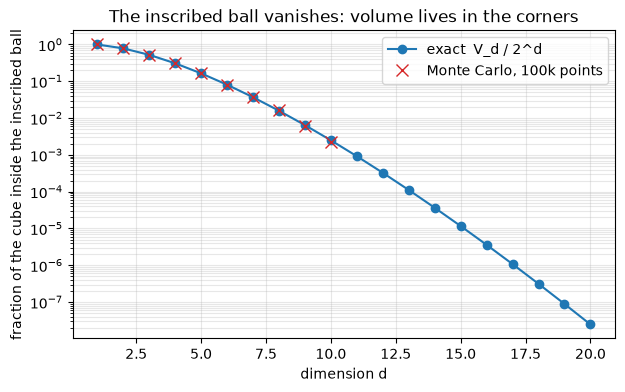

fraction of the cube inside the ball:  d=2: 0.7854   d=3: 0.5236   d=10: 0.00249   d=20: 2.46e-08
fraction of a ball within 90% of its radius, 0.9^d:  d=10: 0.349   d=100: 2.7e-05


In [20]:
from scipy.special import gamma

def ball_volume(d, r=1.0):
    return np.pi ** (d / 2) / gamma(d / 2 + 1) * r ** d

ds = np.arange(1, 21)
ratio = np.array([ball_volume(d) / 2 ** d for d in ds])
mc = []
for d in range(1, 11):                                   # Monte Carlo: fraction of cube points inside the ball
    P = rng.uniform(-1, 1, size=(100_000, d))
    mc.append(np.mean(np.sum(P ** 2, axis=1) <= 1))

fig, ax = plt.subplots()
ax.semilogy(ds, ratio, "o-", label="exact  V_d / 2^d")
ax.semilogy(range(1, 11), mc, "x", ms=9, color="C3", label="Monte Carlo, 100k points")
ax.set_xlabel("dimension d"); ax.set_ylabel("fraction of the cube inside the inscribed ball")
ax.set_title("The inscribed ball vanishes: volume lives in the corners"); ax.legend(); ax.grid(alpha=0.3, which="both")
plt.show()
print("fraction of the cube inside the ball:  d=2: %.4f   d=3: %.4f   d=10: %.5f   d=20: %.2e" % (ratio[1], ratio[2], ratio[9], ratio[19]))
print("fraction of a ball within 90%% of its radius, 0.9^d:  d=10: %.3f   d=100: %.1e" % (0.9 ** 10, 0.9 ** 100))

**Notice that** the Monte Carlo crosses sit on the exact curve, and that the curve collapses fast: by $d = 10$ the ball fills a quarter of one per cent of the cube, by $d = 20$ about one point in 40 million. Almost all of the cube's volume is in its corners, far from the centre. The same formula says that a ball keeps its volume near its surface: the fraction within 90% of the radius is $0.9^d$, only $0.35$ at $d = 10$ and $2.7 \times 10^{-5}$ at $d = 100$ (printed above).

Fourth surprise: **thin shells.** A standard Gaussian sample $\mathbf{x} \in \mathbb{R}^d$ has $\|\mathbf{x}\|^2 \sim \chi^2_d$, with mean $d$ and standard deviation $\sqrt{2d}$, so $\|\mathbf{x}\|$ is about $\sqrt d \pm 0.7$ for large $d$: the radius grows, the thickness does not. We draw 5,000 samples in each of four dimensions and plot $\|\mathbf{x}\| - \sqrt d$.

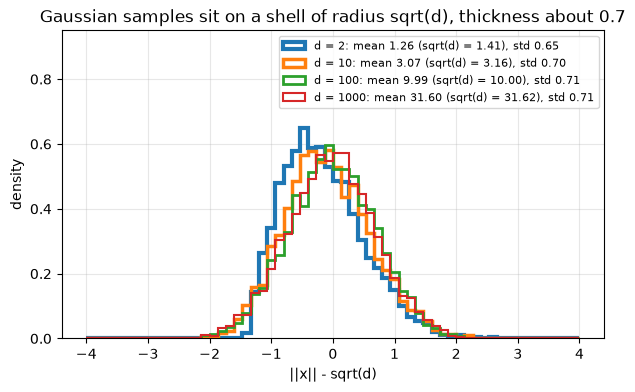

In [21]:
g = np.random.default_rng(3)                              # own generator, so the shared stream above is untouched
fig, ax = plt.subplots()
for d, col, lw in zip([2, 10, 100, 1000], ["C0", "C1", "C2", "C3"], [3, 2.5, 2, 1.5]):
    radius = np.linalg.norm(g.normal(size=(5000, d)), axis=1)        # ||x|| for 5000 standard Gaussian samples in R^d
    ax.hist(radius - np.sqrt(d), bins=60, range=(-4, 4), density=True, histtype="step", lw=lw, color=col,
            label=f"d = {d}: mean {radius.mean():.2f} (sqrt(d) = {np.sqrt(d):.2f}), std {radius.std():.2f}")
ax.set_ylim(0, 0.95)                                                 # head-room for the legend
ax.set_xlabel("||x|| - sqrt(d)"); ax.set_ylabel("density")
ax.set_title("Gaussian samples sit on a shell of radius sqrt(d), thickness about 0.7")
ax.legend(fontsize=8, loc="upper right"); ax.grid(alpha=0.3)
plt.show()

**Notice that** all four histograms have almost the same width — a standard deviation of about $0.7$ once $d \ge 10$ (the legend reads 0.70 at $d = 10$ and 0.71 from $d = 100$ on; the exact value tends to $1/\sqrt 2 \approx 0.707$) — while the radius they sit on grows like $\sqrt d$. A 1000-dimensional Gaussian cloud is a shell of radius 31.6 and thickness 0.7: a typical sample is never near the origin, although the density is highest there. This is the thin-shell statement of the guide, and the geometry of the latent spaces in Module 18.

**Where this bites in deep learning.** Attention scores are dot products $\mathbf{q}\cdot\mathbf{k}$ of $d_k$-dimensional vectors. For roughly unit-variance coordinates that dot product has standard deviation $\sqrt{d_k}$, so without correction the scores for different keys are spread over tens of units and the softmax saturates onto a single key. Dividing by $\sqrt{d_k}$ brings the spread back to one — this is the only reason the $\sqrt{d_k}$ appears in the transformer's attention formula.

In [22]:
d_k, n_keys = 64, 10
K = rng.normal(size=(n_keys, d_k))
Qs = rng.normal(size=(2000, d_k))                         # many queries, to measure the spread of q.k reliably
all_scores = Qs @ K.T                                     # (2000, 10): one dot product per query-key pair
print("std of the raw scores q.k over 20000 pairs: %.2f   (theory: sqrt(d_k) = %.1f)" % (all_scores.std(), np.sqrt(d_k)))
print("std after dividing by sqrt(d_k)           : %.2f" % (all_scores / np.sqrt(d_k)).std())

def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

scores = all_scores[0]                                    # the ten scores of the first query
print("attention weights, raw scores        :", softmax(scores))
print("attention weights, scores / sqrt(d_k):", softmax(scores / np.sqrt(d_k)))
print("largest weight: raw %.3f  vs  scaled %.3f" % (softmax(scores).max(), softmax(scores / np.sqrt(d_k)).max()))

std of the raw scores q.k over 20000 pairs: 8.26   (theory: sqrt(d_k) = 8.0)
std after dividing by sqrt(d_k)           : 1.03
attention weights, raw scores        : [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
attention weights, scores / sqrt(d_k): [0.4317 0.0444 0.0385 0.0935 0.1064 0.0665 0.0449 0.0256 0.0371 0.1113]
largest weight: raw 1.000  vs  scaled 0.432


That was a single query. To see the typical behaviour, repeat the experiment for 500 queries and for key dimensions from 4 to 1024, and record the median of the largest attention weight over the ten keys: $1/10$ would be perfectly uniform attention, $1$ a hard choice of one key.

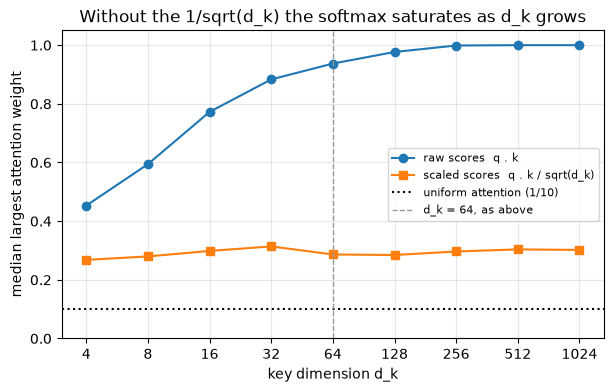

d_k    : [4, 8, 16, 32, 64, 128, 256, 512, 1024]
raw    : [0.453 0.594 0.772 0.883 0.937 0.977 0.999 1.    1.   ]
scaled : [0.268 0.28  0.298 0.314 0.287 0.285 0.297 0.304 0.302]


In [23]:
g = np.random.default_rng(1)                              # own generator, so the shared stream above is untouched

def softmax_rows(Z):
    e = np.exp(Z - Z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

dks = [4, 8, 16, 32, 64, 128, 256, 512, 1024]
raw_max, scaled_max = [], []
for dk in dks:
    Kd, Qd = g.normal(size=(10, dk)), g.normal(size=(500, dk))      # 10 keys and 500 queries of width dk
    Sd = Qd @ Kd.T                                                  # (500, 10) raw scores
    raw_max.append(np.median(softmax_rows(Sd).max(axis=1)))
    scaled_max.append(np.median(softmax_rows(Sd / np.sqrt(dk)).max(axis=1)))

fig, ax = plt.subplots()
ax.semilogx(dks, raw_max, "o-", base=2, label="raw scores  q . k")
ax.semilogx(dks, scaled_max, "s-", base=2, label="scaled scores  q . k / sqrt(d_k)")
ax.axhline(0.1, color="k", ls=":", label="uniform attention (1/10)")
ax.axvline(64, color="0.6", ls="--", lw=1, label="d_k = 64, as above")
ax.set_ylim(0, 1.05); ax.set_xticks(dks); ax.set_xticklabels([str(k) for k in dks]); ax.minorticks_off()
ax.set_xlabel("key dimension d_k"); ax.set_ylabel("median largest attention weight")
ax.set_title("Without the 1/sqrt(d_k) the softmax saturates as d_k grows")
ax.legend(fontsize=8); ax.grid(alpha=0.3, which="both")
plt.show()
print("d_k    :", dks)
print("raw    :", np.round(raw_max, 3))
print("scaled :", np.round(scaled_max, 3))

**Notice that** with raw scores the typical largest attention weight climbs with $d_k$ — about $0.94$ at the $d_k = 64$ used above, and $1.000$ to three decimals from $d_k = 512$ on. The softmax has collapsed to a hard arg-max, whose gradient is zero almost everywhere. After dividing by $\sqrt{d_k}$ it stays near $0.3$ at every width: the scaling makes the layer's behaviour independent of the head size.

> **Try it yourself:** add a third curve that divides the scores by `d_k` instead of `np.sqrt(d_k)`. It sinks towards the dotted $1/10$ line — the weights become nearly equal and attention can no longer tell the keys apart. Why is that too much?

## Summary

- A vector is simultaneously an arrow, a point and a data record; addition and scaling are component-wise, and `rank` tells you whether a set of vectors is independent.
- Norms are rulers: $L_2$ (round ball), $L_1$ (diamond — corners give sparsity), $L_\infty$ (square); distances depend on the norm *and* on how features are scaled.
- The dot product is a weighted sum and a measure of alignment at once: $\mathbf{u}\cdot\mathbf{v} = \|\mathbf{u}\|\|\mathbf{v}\|\cos\theta$, verified numerically along with Cauchy–Schwarz and the triangle inequality.
- Cosine similarity compares direction only; it ranked the long ML article first where Euclidean distance buried it. All similarities to a query come from one matrix–vector product.
- Projection $\mathbf{p} = \frac{\mathbf{a}\cdot\mathbf{b}}{\mathbf{b}\cdot\mathbf{b}}\mathbf{b}$ is the best approximation on a line; the residual is orthogonal; the squared error is a parabola.
- Gram–Schmidt builds an orthonormal basis by subtracting projections; coordinates are then dot products and Parseval preserves length; `np.linalg.qr` agrees up to signs.
- A linear classifier is a hyperplane $\mathbf{w}\cdot\mathbf{x} + b = 0$ with normal $\mathbf{w}$; signed distance $(\mathbf{w}\cdot\mathbf{x} + b)/\|\mathbf{w}\|$ is invariant to rescaling $(\mathbf{w}, b)$.
- In high dimension random vectors are nearly orthogonal (cosine spread $1/\sqrt d$), distances concentrate ($\approx 0.59/\sqrt d$ relative spread), the inscribed ball's share of the cube vanishes, and Gaussian samples sit on a thin shell of radius $\sqrt d$. These facts explain why attention divides by $\sqrt{d_k}$ (without it the softmax saturates) and why $k$-NN fails on raw high-dimensional inputs.

**Next:** open `exercises.ipynb` and implement these objects yourself — norms without `np.linalg.norm`, top-$k$ cosine retrieval, projections, Gram–Schmidt, signed distances, a distance-concentration experiment, and a small recommender built from user–user cosine similarity. Reference solutions are in `solutions.ipynb`.